In [8]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo
glass = fetch_ucirepo( id = 42 )
X = glass.data.features
y = glass.data.targets.values.ravel()

In [9]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

from sklearn.preprocessing import StandardScaler

zscore_scaler = StandardScaler()

X_train_std = zscore_scaler.fit_transform(X_train)
X_test_std = zscore_scaler.transform(X_test)

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score


# C:     0.1, 1, 10, 100       (regularização: baixo = simples, alto = complexo)
# gamma: 0.001, 0.01, 0.1, 1   (alcance de cada ponto: baixo = suave, alto = local)
# OBS: Lembra que os parâmetros de np.logspace são os expoentes
C_VALORES = np.logspace(-1, 2, 4)
GAMMA_VALORES = np.logspace(-3, 0, 4)

grids = {
    "linear": {"kernel": ["linear"],
               "C": np.logspace(-1, 1, 3)},                 # 0.1, 1, 10
    "poly":   {"kernel": ["poly"],
               "degree": [2, 3],
               "C": np.logspace(-1, 1, 3),                  # 0.1, 1, 10
               "gamma": np.logspace(-2, 0, 3)},             # 0.01, 0.1, 1
    "rbf":    {"kernel": ["rbf"],
               "C": C_VALORES,
               "gamma": GAMMA_VALORES},
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resumo = []        # 1 linha por modelo (tabela final)
historico_cv = []  # todas as combinações testadas (para o mapa de calor)

# Gambiarra inteligente pra pegar os dois em um loop só
for usar_scaling in [False, True]:
    nome_scaling = "COM scaling" if usar_scaling else "SEM scaling"
    X_treino = X_train_std if usar_scaling else X_train
    X_teste = X_test_std if usar_scaling else X_test

    for kernel, grid in grids.items():
        busca = GridSearchCV(SVC(), grid, cv=cv, scoring="accuracy",
                             n_jobs=-1, return_train_score=True)
        busca.fit(X_treino, y_train)

        acc_teste = accuracy_score(y_test, busca.best_estimator_.predict(X_teste))

        i = busca.best_index_
        acc_validacao = busca.cv_results_["mean_test_score"][i]    # média nos folds de validação
        desvio_validacao = busca.cv_results_["std_test_score"][i]  # estabilidade entre folds
        acc_treino = busca.cv_results_["mean_train_score"][i]      # média nos folds de treino

        df_busca = pd.DataFrame(busca.cv_results_)
        df_busca["scaling"] = nome_scaling
        df_busca["kernel"] = kernel
        historico_cv.append(df_busca)

        resumo.append({
            "scaling": nome_scaling,
            "kernel": kernel,
            "melhores_params": {k: (v.item() if hasattr(v, "item") else v)
                                for k, v in busca.best_params_.items() if k != "kernel"},
            "acc_treino": round(acc_treino, 4),
            "acc_validacao": round(acc_validacao, 4),
            "desvio_validacao": round(desvio_validacao, 4),
            "acc_teste": round(acc_teste, 4),
            # gap grande = sinal de overfitting
            "gap_treino_validacao": round(acc_treino - acc_validacao, 4),
        })

df_resumo = pd.DataFrame(resumo)
print(df_resumo.to_string(index=False))

df_historico = pd.concat(historico_cv, ignore_index=True)

    scaling kernel                        melhores_params  acc_treino  acc_validacao  desvio_validacao  acc_teste  gap_treino_validacao
SEM scaling linear                            {'C': 10.0}      0.7397         0.6548            0.0636     0.7209                0.0850
SEM scaling   poly {'C': 0.1, 'degree': 3, 'gamma': 0.01}      0.7587         0.6897            0.0527     0.7209                0.0690
SEM scaling    rbf              {'C': 10.0, 'gamma': 0.1}      0.8055         0.6956            0.0455     0.7209                0.1099
COM scaling linear                             {'C': 1.0}      0.7266         0.6548            0.0688     0.6977                0.0718
COM scaling   poly {'C': 10.0, 'degree': 2, 'gamma': 1.0}      0.9473         0.6371            0.1148     0.7209                0.3102
COM scaling    rbf               {'C': 1.0, 'gamma': 0.1}      0.7967         0.6901            0.0395     0.7209                0.1067



Análise da validação cruzada:
    scaling kernel validacao_media_desvio  acc_treino  gap_treino_validacao  acc_teste
SEM scaling linear        0.6548 ± 0.0636      0.7397                0.0850     0.7209
SEM scaling   poly        0.6897 ± 0.0527      0.7587                0.0690     0.7209
SEM scaling    rbf        0.6956 ± 0.0455      0.8055                0.1099     0.7209
COM scaling linear        0.6548 ± 0.0688      0.7266                0.0718     0.6977
COM scaling   poly        0.6371 ± 0.1148      0.9473                0.3102     0.7209
COM scaling    rbf        0.6901 ± 0.0395      0.7967                0.1067     0.7209


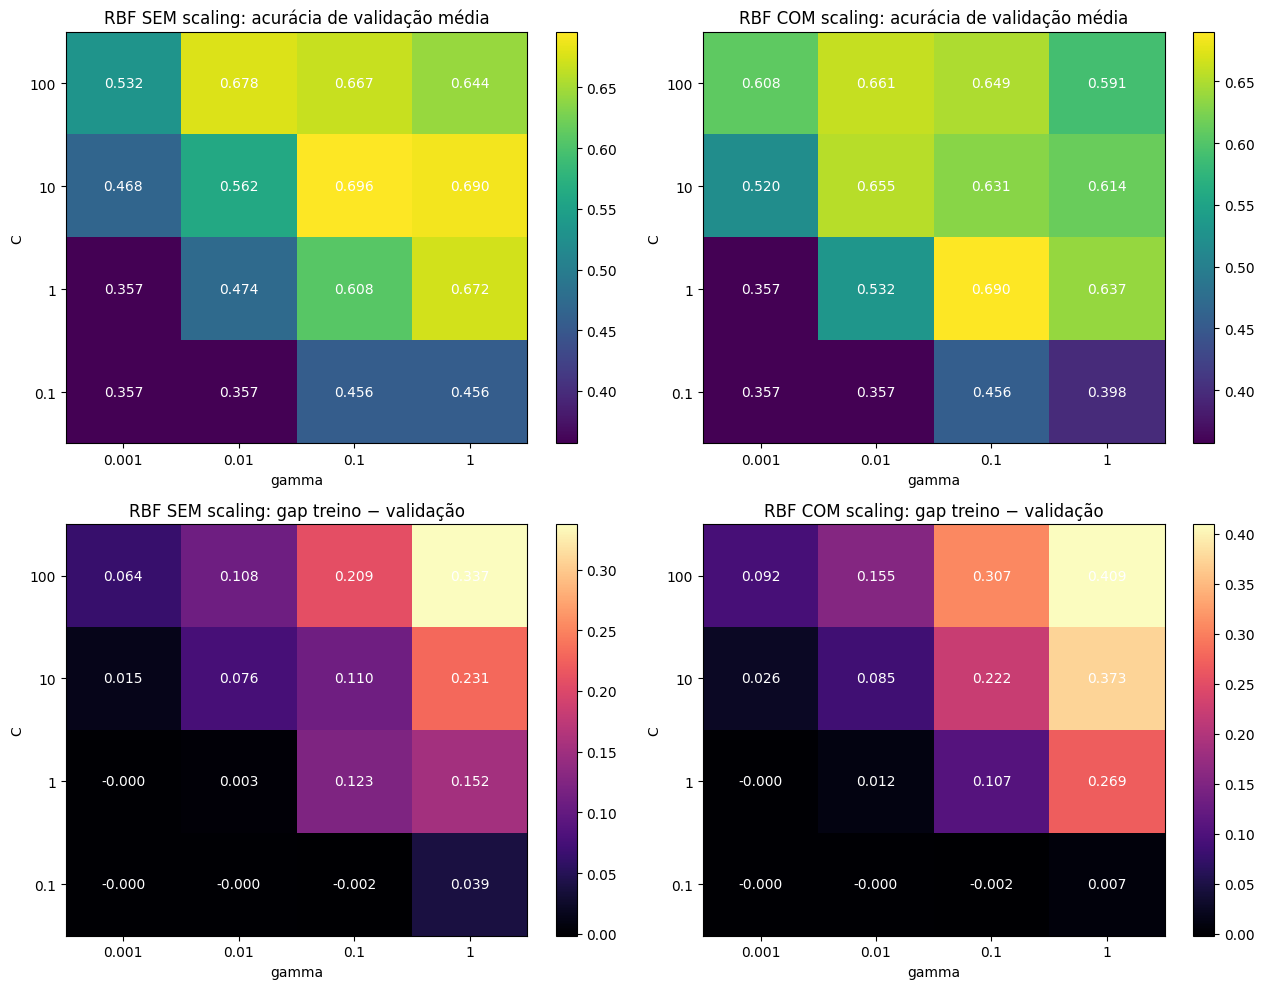

SEM scaling: melhor RBF com C=10, gamma=0.1, validação=0.6956, gap=0.1099
COM scaling: melhor RBF com C=1, gamma=0.1, validação=0.6901, gap=0.1067


In [13]:
df_resumo["validacao_media_desvio"] = df_resumo.apply(
    lambda linha: f"{linha['acc_validacao']:.4f} ± {linha['desvio_validacao']:.4f}", axis=1)

print("\nAnálise da validação cruzada:")
print(df_resumo[["scaling", "kernel", "validacao_media_desvio",
                 "acc_treino", "gap_treino_validacao", "acc_teste"]]
      .to_string(index=False))

df_rbf = df_historico[df_historico["kernel"] == "rbf"].copy()
df_rbf["C"] = df_rbf["param_C"].astype(float)
df_rbf["gamma"] = df_rbf["param_gamma"].astype(float)
df_rbf["acc_validacao"] = df_rbf["mean_test_score"]   # "test" aqui é a validação da CV
df_rbf["acc_treino"] = df_rbf["mean_train_score"]
df_rbf["gap"] = df_rbf["acc_treino"] - df_rbf["acc_validacao"]

# Gráfico (SOS)
def desenhar_mapa(ax, matriz, titulo, cmap, formato):
    img = ax.imshow(matriz.values, cmap=cmap, origin="lower", aspect="auto")
    ax.set_xticks(range(matriz.shape[1]))
    ax.set_xticklabels([f"{g:g}" for g in matriz.columns])
    ax.set_yticks(range(matriz.shape[0]))
    ax.set_yticklabels([f"{c:g}" for c in matriz.index])
    ax.set_xlabel("gamma")
    ax.set_ylabel("C")
    ax.set_title(titulo)
    # escreve o valor dentro de cada célula
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            ax.text(j, i, format(matriz.values[i, j], formato),
                    ha="center", va="center", color="w")
    plt.colorbar(img, ax=ax)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for coluna, nome_scaling in enumerate(["SEM scaling", "COM scaling"]):
    dados = df_rbf[df_rbf["scaling"] == nome_scaling]
    mat_validacao = dados.pivot(index="C", columns="gamma", values="acc_validacao")
    mat_gap = dados.pivot(index="C", columns="gamma", values="gap")

    desenhar_mapa(axes[0, coluna], mat_validacao,
                  f"RBF {nome_scaling}: acurácia de validação média", "viridis", ".3f")
    desenhar_mapa(axes[1, coluna], mat_gap,
                  f"RBF {nome_scaling}: gap treino − validação", "magma", ".3f")

plt.tight_layout()
plt.show()

for nome_scaling in ["SEM scaling", "COM scaling"]:
    dados = df_rbf[df_rbf["scaling"] == nome_scaling]
    melhor = dados.loc[dados["acc_validacao"].idxmax()]
    print(f"{nome_scaling}: melhor RBF com C={melhor['C']:g}, gamma={melhor['gamma']:g}, "
          f"validação={melhor['acc_validacao']:.4f}, gap={melhor['gap']:.4f}")

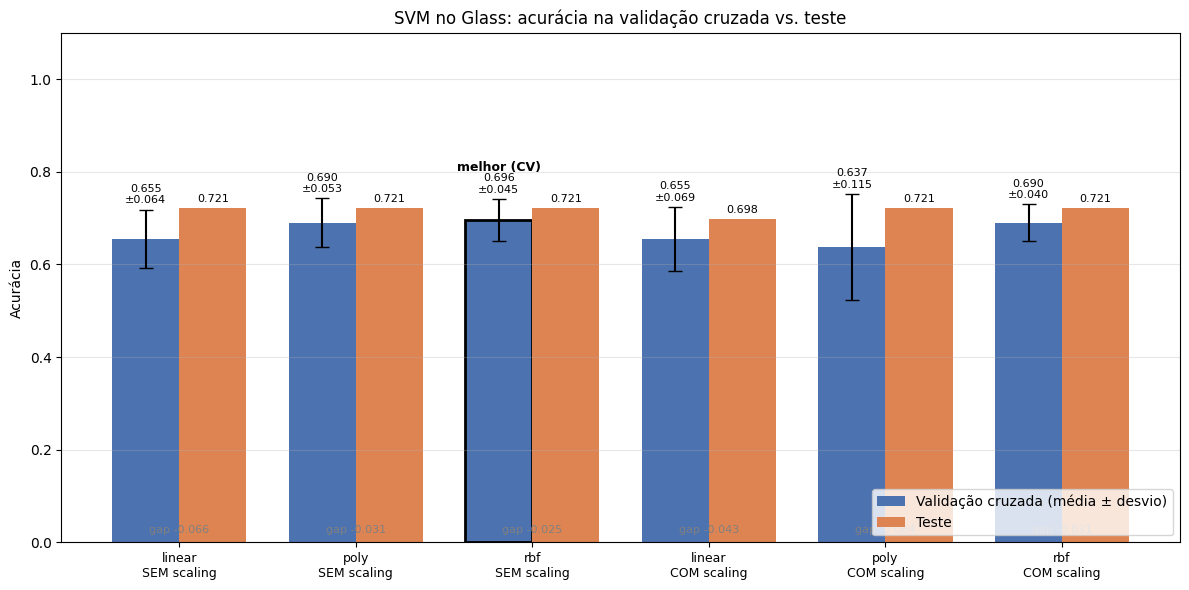

In [14]:
import numpy as np
import matplotlib.pyplot as plt

dados = df_resumo.reset_index(drop=True)
dados["modelo"] = dados["kernel"] + "\n" + dados["scaling"]   # rótulo do eixo x
# gap diferente do mapa de calor: aqui é validação - teste
dados["gap_validacao_teste"] = dados["acc_validacao"] - dados["acc_teste"]

posicoes = np.arange(len(dados))
largura = 0.38

# Melhor modelo escolhido pela validação, nunca pelo teste
idx_melhor = dados["acc_validacao"].idxmax()

fig, ax = plt.subplots(figsize=(12, 6))

barras_validacao = ax.bar(posicoes - largura / 2, dados["acc_validacao"], largura,
                          yerr=dados["desvio_validacao"], capsize=5,
                          color="#4C72B0", label="Validação cruzada (média ± desvio)")
barras_teste = ax.bar(posicoes + largura / 2, dados["acc_teste"], largura,
                      color="#DD8452", label="Teste")

for i, linha in dados.iterrows():
    # valor da validação, acima da barra de erro
    ax.annotate(f"{linha['acc_validacao']:.3f}\n±{linha['desvio_validacao']:.3f}",
                (posicoes[i] - largura / 2, linha["acc_validacao"] + linha["desvio_validacao"]),
                ha="center", va="bottom", fontsize=8,
                xytext=(0, 3), textcoords="offset points")
    # valor do teste
    ax.annotate(f"{linha['acc_teste']:.3f}",
                (posicoes[i] + largura / 2, linha["acc_teste"]),
                ha="center", va="bottom", fontsize=8,
                xytext=(0, 3), textcoords="offset points")
    # gap validação - teste, perto da base
    ax.text(posicoes[i], 0.02, f"gap {linha['gap_validacao_teste']:+.3f}",
            ha="center", fontsize=8, color="gray")

barras_validacao[idx_melhor].set_edgecolor("black")
barras_validacao[idx_melhor].set_linewidth(2)
ax.text(posicoes[idx_melhor] - largura / 2,
        dados.loc[idx_melhor, "acc_validacao"] + dados.loc[idx_melhor, "desvio_validacao"] + 0.06,
        "melhor (CV)", ha="center", fontsize=9, fontweight="bold")

ax.set_xticks(posicoes)
ax.set_xticklabels(dados["modelo"], fontsize=9)
ax.set_ylabel("Acurácia")
ax.set_ylim(0, 1.1)
ax.set_title("SVM no Glass: acurácia na validação cruzada vs. teste")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()